In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns

# Load the data

In [2]:
data_folder = Path('data')
timestep = 2 # seconds

data = pd.DataFrame()
for file in data_folder.glob('*.csv'):
    df = pd.read_csv(file)
    data = pd.concat([data, df], ignore_index=True)


In [3]:
data.head()

,,Width,Height,Angle,Type
0,1,26.265,14.0,-26.4230,anterograde
1,2,16.583,10.0,-28.6397,anterograde
2,3,21.321,17.0,-37.0191,anterograde
3,4,18.025,5.0,-12.5816,anterograde
4,5,11.742,6.0,-23.1563,anterograde


In [4]:
data['time'] = data['Height'] * timestep
data['speed'] = data['Width']/data['time']

In [5]:
data.to_csv('plot_data.csv')

In [6]:
data = pd.read_csv('plot_data.csv')

In [7]:
data.groupby('Type')['speed'].median()

Type
anterograde    1.811964
retrograde     0.495687
Name: speed, dtype: float64

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is depr

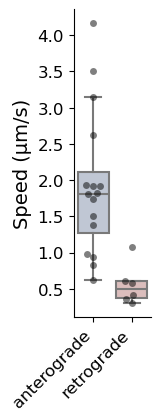

In [8]:
fig, ax = plt.subplots(figsize=(1, 4))
sns.boxplot(data=data, x='Type', y='speed', palette='vlag', showfliers=False)
sns.swarmplot(data=data, x='Type', y='speed', color='black', alpha=0.5)
plt.ylabel('Speed (µm/s)', fontsize=14)
plt.xlabel('')
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()
#plt.savefig('single_mito_kymos.png', dpi=300, bbox_inches='tight')